# A2 — Predicting Concrete Compressive Strength
AI-101 ML Assignment | Pool A | Supervised regression

**Sections follow the report:** 1 Introduction, 2 Problem, 3 Dataset, 4 Statistics, 5 Methodology, 6 Results and Analysis.

In [1]:
# !pip install -q ucimlrepo scikit-learn pandas matplotlib seaborn jinja2
import os, json, time, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
print('Python', platform.python_version(), '| sklearn', sklearn.__version__, '| seed', SEED)

Python 3.14.3 | sklearn 1.9.1 | seed 42


## 3. Dataset Used — load and clean

In [2]:
from ucimlrepo import fetch_ucirepo
ds = fetch_ucirepo(id=165)           # UCI Concrete Compressive Strength
X = ds.data.features.copy()
y = ds.data.targets.iloc[:, 0].copy()
X.columns = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_agg', 'fine_agg', 'age']
y.name = 'strength'
df = pd.concat([X, y], axis=1)

n_raw = len(df)
n_missing = int(df.isna().sum().sum())
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)          # cleaning step 1: exact duplicates
print(f'rows raw={n_raw} | missing cells={n_missing} | duplicates removed={n_dup} | rows after cleaning={len(df)}')
df.head()

rows raw=1030 | missing cells=0 | duplicates removed=25 | rows after cleaning=1005


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 4. Dataset Statistics and EDA

In [3]:
desc = df.describe().T[['mean', 'std', 'min', 'max']]
print(desc.round(2))
print('\nSkew of each column:\n', df.skew().round(2))
print('\nTarget mean +- sd: %.2f +- %.2f MPa (range %.2f to %.2f)' % (df.strength.mean(), df.strength.std(), df.strength.min(), df.strength.max()))
print('\nCorrelation with target:\n', df.corr()['strength'].drop('strength').sort_values(ascending=False).round(3))

                    mean     std     min     max
cement            278.63  104.34  102.00   540.0
slag               72.04   86.17    0.00   359.4
fly_ash            55.54   64.21    0.00   200.1
water             182.08   21.34  121.80   247.0
superplasticizer    6.03    5.92    0.00    32.2
coarse_agg        974.38   77.58  801.00  1145.0
fine_agg          772.69   80.34  594.00   992.6
age                45.86   63.73    1.00   365.0
strength           35.25   16.28    2.33    82.6

Skew of each column:
 cement              0.56
slag                0.86
fly_ash             0.50
water               0.03
superplasticizer    0.98
coarse_agg         -0.07
fine_agg           -0.25
age                 3.25
strength            0.40
dtype: float64

Target mean +- sd: 35.25 +- 16.28 MPa (range 2.33 to 82.60)

Correlation with target:
 cement              0.488
superplasticizer    0.344
age                 0.337
slag                0.103
fly_ash            -0.081
coarse_agg         -0.145
fin

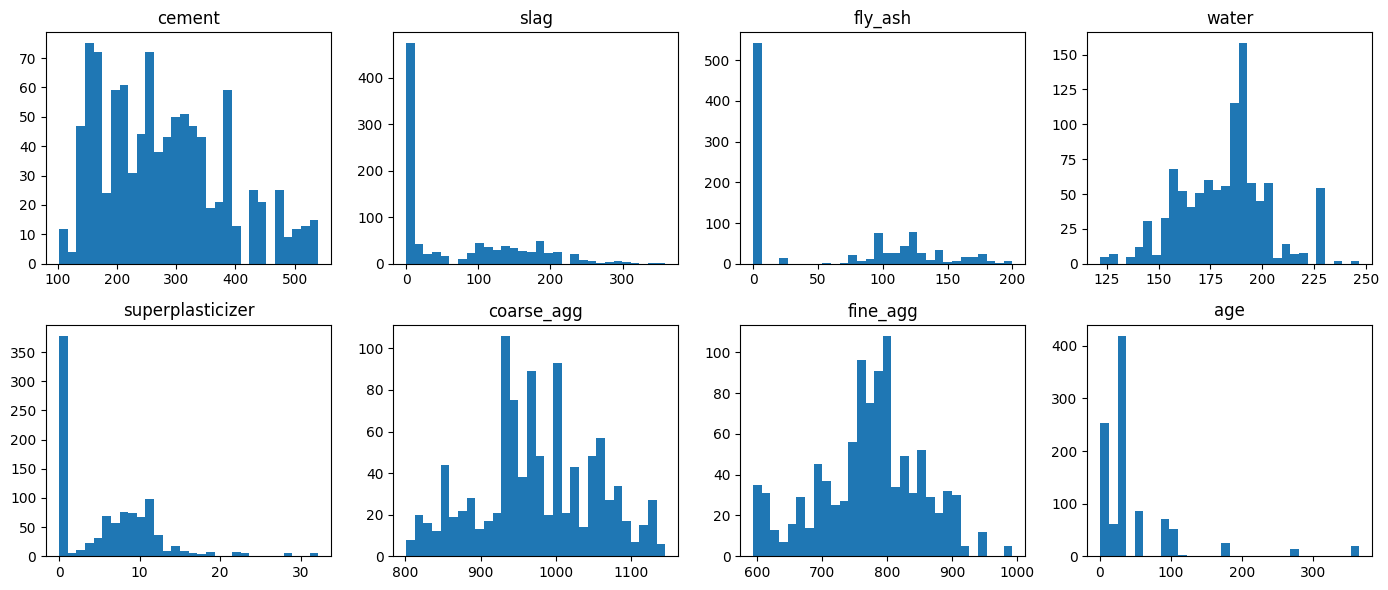

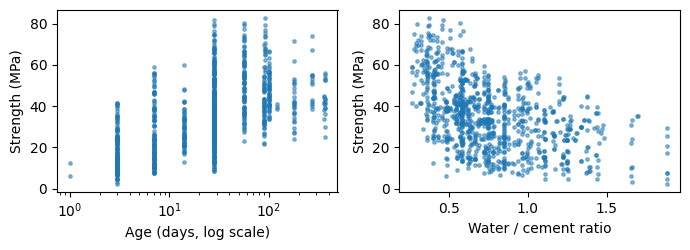

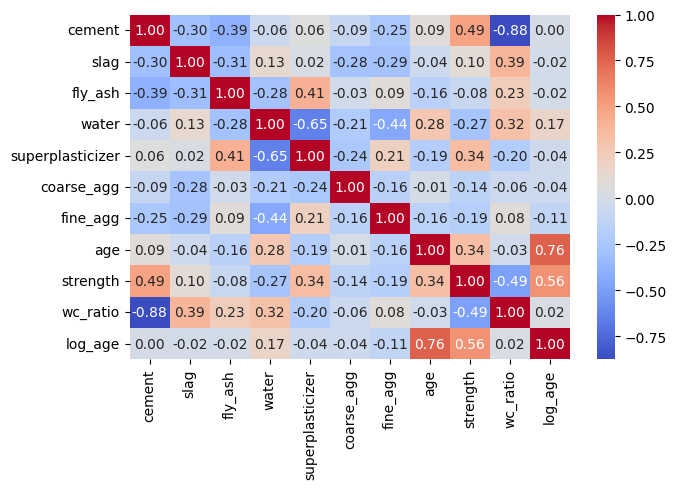

In [4]:
df['wc_ratio'] = df['water'] / df['cement']      # used for EDA and for feature engineering
df['log_age'] = np.log(df['age'])

fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for a, c in zip(ax.ravel(), ['cement','slag','fly_ash','water','superplasticizer','coarse_agg','fine_agg','age']):
    a.hist(df[c], bins=30); a.set_title(c)
plt.tight_layout(); plt.savefig('figures/a2_histograms.png', dpi=200); plt.show()

# KEY EDA FIGURE for the report: strength vs age and vs water/cement ratio
fig, ax = plt.subplots(1, 2, figsize=(7, 2.6))
ax[0].scatter(df['age'], df['strength'], s=6, alpha=.5); ax[0].set_xscale('log')
ax[0].set_xlabel('Age (days, log scale)'); ax[0].set_ylabel('Strength (MPa)')
ax[1].scatter(df['wc_ratio'], df['strength'], s=6, alpha=.5)
ax[1].set_xlabel('Water / cement ratio'); ax[1].set_ylabel('Strength (MPa)')
plt.tight_layout(); plt.savefig('figures/a2_eda.png', dpi=300); plt.show()

plt.figure(figsize=(7, 5)); sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.tight_layout(); plt.savefig('figures/a2_corr.png', dpi=200); plt.show()

## 5. Methodology
### 5.2 Data split (80/20, fixed seed). Scaling lives inside pipelines, so it is fitted on training data only.

In [5]:
BASE = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_agg', 'fine_agg', 'age']
ENG = BASE + ['wc_ratio', 'log_age']
FEATURE_SETS = {'base': BASE, 'engineered': ENG}

train_df, test_df = train_test_split(df, test_size=0.20, random_state=SEED)
ytr, yte = train_df['strength'].values, test_df['strength'].values
print('train', len(train_df), '| test', len(test_df))
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

train 804 | test 201


### 5.1 / 5.3 Models and hyperparameter search spaces (5-fold CV on the training set only)

In [6]:
def make_models():
    return {
        'linear': (Pipeline([('sc', StandardScaler()), ('lr', LinearRegression())]), {}),
        'poly_ridge': (Pipeline([('sc', StandardScaler()), ('poly', PolynomialFeatures(include_bias=False)), ('ridge', Ridge())]),
                       {'poly__degree': [2, 3], 'ridge__alpha': [0.01, 0.1, 1, 10, 100]}),
        'rf': (RandomForestRegressor(random_state=SEED, n_jobs=-1),
               {'n_estimators': [200, 500], 'max_depth': [None, 10, 20], 'min_samples_leaf': [1, 2]}),
        'gbr': (GradientBoostingRegressor(random_state=SEED),
                {'n_estimators': [200, 500], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3, 4]}),
        'mlp': (Pipeline([('sc', StandardScaler()), ('mlp', MLPRegressor(max_iter=2000, early_stopping=True, random_state=SEED))]),
                {'mlp__hidden_layer_sizes': [(64, 64), (128, 64)], 'mlp__alpha': [1e-4, 1e-2], 'mlp__learning_rate_init': [1e-3, 1e-2]}),
    }

def test_metrics(model, X, y):
    p = model.predict(X)
    return dict(MAE=mean_absolute_error(y, p), RMSE=np.sqrt(mean_squared_error(y, p)), R2=r2_score(y, p))

rows, fitted, best_params = [], {}, {}
for fs_name, cols in FEATURE_SETS.items():
    for name, (est, grid) in make_models().items():
        t0 = time.time()
        gs = GridSearchCV(est, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1, refit=True)
        gs.fit(train_df[cols], ytr)
        i = gs.best_index_
        cv_rmse, cv_std = -gs.cv_results_['mean_test_score'][i], gs.cv_results_['std_test_score'][i]
        m = test_metrics(gs.best_estimator_, test_df[cols], yte)          # test set used once per model
        rows.append(dict(features=fs_name, model=name, CV_RMSE=cv_rmse, CV_std=cv_std, **m))
        fitted[(fs_name, name)] = gs.best_estimator_
        best_params[f'{fs_name}/{name}'] = {k: str(v) for k, v in gs.best_params_.items()}
        print(f'{fs_name:10s} {name:11s} CV RMSE {cv_rmse:.2f}+-{cv_std:.2f} | test RMSE {m["RMSE"]:.2f} MAE {m["MAE"]:.2f} R2 {m["R2"]:.3f} ({time.time()-t0:.0f}s)')

res = pd.DataFrame(rows)
res.to_csv('results/a2_results.csv', index=False)
json.dump(best_params, open('results/a2_best_params.json', 'w'), indent=2)
print(json.dumps(best_params, indent=2))

base       linear      CV RMSE 10.20+-0.15 | test RMSE 11.19 MAE 8.90 R2 0.580 (6s)
base       poly_ridge  CV RMSE 6.42+-0.40 | test RMSE 6.95 MAE 4.98 R2 0.838 (0s)
base       rf          CV RMSE 5.35+-0.49 | test RMSE 5.20 MAE 3.53 R2 0.909 (29s)
base       gbr         CV RMSE 4.66+-0.47 | test RMSE 4.39 MAE 2.93 R2 0.935 (12s)
base       mlp         CV RMSE 5.88+-0.36 | test RMSE 5.99 MAE 4.33 R2 0.880 (22s)
engineered linear      CV RMSE 6.85+-0.18 | test RMSE 7.45 MAE 5.77 R2 0.814 (0s)
engineered poly_ridge  CV RMSE 5.45+-0.50 | test RMSE 5.49 MAE 3.83 R2 0.899 (0s)
engineered rf          CV RMSE 5.15+-0.33 | test RMSE 4.86 MAE 3.35 R2 0.921 (31s)
engineered gbr         CV RMSE 4.47+-0.33 | test RMSE 4.29 MAE 2.83 R2 0.938 (15s)
engineered mlp         CV RMSE 5.38+-0.33 | test RMSE 4.86 MAE 3.40 R2 0.921 (22s)
{
  "base/linear": {},
  "base/poly_ridge": {
    "poly__degree": "3",
    "ridge__alpha": "10"
  },
  "base/rf": {
    "max_depth": "20",
    "min_samples_leaf": "1",
    

## 6.1 Results

In [11]:
pd.set_option('display.float_format', '{:.3f}'.format)
display(res)
print('\nTest RMSE: base vs engineered')
display(res.pivot(index='model', columns='features', values='RMSE'))
print('\nLaTeX for Table 3 (engineered features):')
print(res[res.features == 'engineered'][['model', 'MAE', 'RMSE', 'R2']].to_latex(index=False, float_format='%.2f'))

,features,model,CV_RMSE,CV_std,MAE,RMSE,R2
0,base,linear,10.202,0.153,8.895,11.191,0.580
1,base,poly_ridge,6.415,0.396,4.977,6.949,0.838
2,base,rf,5.354,0.489,3.528,5.204,0.909
3,base,gbr,4.665,0.466,2.934,4.387,0.935
4,base,mlp,5.879,0.362,4.326,5.990,0.880
5,engineered,linear,6.852,0.178,5.769,7.448,0.814
6,engineered,poly_ridge,5.450,0.499,3.826,5.493,0.899
7,engineered,rf,5.152,0.327,3.355,4.858,0.921
8,engineered,gbr,4.466,0.332,2.831,4.293,0.938
9,engineered,mlp,5.378,0.332,3.398,4.863,0.921



Test RMSE: base vs engineered


features,base,engineered
model,,
gbr,4.387,4.293
linear,11.191,7.448
mlp,5.990,4.863
poly_ridge,6.949,5.493
rf,5.204,4.858



LaTeX for Table 3 (engineered features):
\begin{tabular}{lrrr}
\toprule
model & MAE & RMSE & R2 \\
\midrule
linear & 5.77 & 7.45 & 0.81 \\
poly_ridge & 3.83 & 5.49 & 0.90 \\
rf & 3.35 & 4.86 & 0.92 \\
gbr & 2.83 & 4.29 & 0.94 \\
mlp & 3.40 & 4.86 & 0.92 \\
\bottomrule
\end{tabular}



Best by CV RMSE: engineered gbr


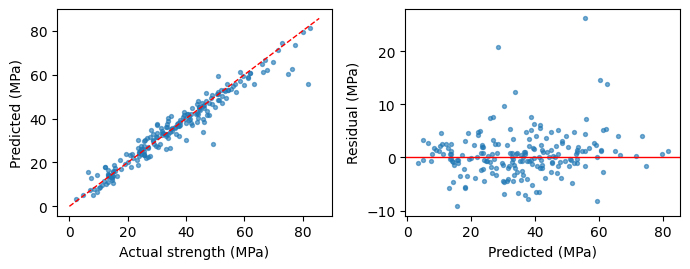

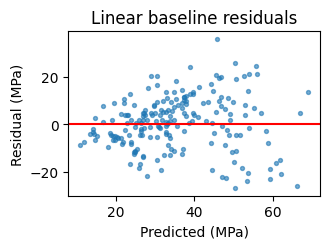

In [8]:
# Best model chosen by CV RMSE (not by test score)
best_row = res.sort_values('CV_RMSE').iloc[0]
fs, nm = best_row['features'], best_row['model']
best = fitted[(fs, nm)]; cols = FEATURE_SETS[fs]
print('Best by CV RMSE:', fs, nm)
pred = best.predict(test_df[cols]); resid = yte - pred

fig, ax = plt.subplots(1, 2, figsize=(7, 2.8))
ax[0].scatter(yte, pred, s=8, alpha=.6); lim = [0, max(yte.max(), pred.max()) + 3]
ax[0].plot(lim, lim, 'r--', lw=1); ax[0].set_xlabel('Actual strength (MPa)'); ax[0].set_ylabel('Predicted (MPa)')
ax[1].scatter(pred, resid, s=8, alpha=.6); ax[1].axhline(0, color='r', lw=1)
ax[1].set_xlabel('Predicted (MPa)'); ax[1].set_ylabel('Residual (MPa)')
plt.tight_layout(); plt.savefig('figures/a2_pred_resid.png', dpi=300); plt.show()

# Linear baseline residuals (for the analysis question about violated assumptions)
lin = fitted[('base', 'linear')]; pl = lin.predict(test_df[BASE])
plt.figure(figsize=(3.4, 2.6)); plt.scatter(pl, yte - pl, s=8, alpha=.6); plt.axhline(0, color='r')
plt.xlabel('Predicted (MPa)'); plt.ylabel('Residual (MPa)'); plt.title('Linear baseline residuals')
plt.tight_layout(); plt.savefig('figures/a2_linear_resid.png', dpi=300); plt.show()

## 6.2 Analysis helpers: error by age band and feature importance

MAE by age band for gbr :
         count  mean
band               
<=7d       56 2.790
8-28d      89 3.470
29-90d     27 2.120
>90d       29 1.600


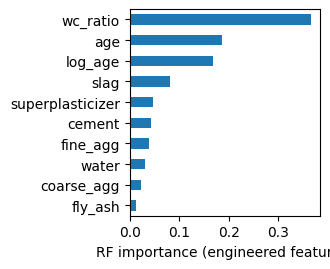

wc_ratio           0.366
age                0.187
log_age            0.169
slag               0.081
superplasticizer   0.046
cement             0.043
fine_agg           0.039
water              0.031
coarse_agg         0.024
fly_ash            0.013
dtype: float64


In [9]:
bands = pd.cut(test_df['age'].values, [0, 7, 28, 90, 400], labels=['<=7d', '8-28d', '29-90d', '>90d'])
err = pd.DataFrame({'band': bands, 'abs_err': np.abs(resid)}).groupby('band', observed=True)['abs_err'].agg(['count', 'mean'])
print('MAE by age band for', nm, ':\n', err.round(2))

rf = fitted[('engineered', 'rf')]
imp = pd.Series(rf.feature_importances_, index=ENG).sort_values()
plt.figure(figsize=(3.4, 2.8)); imp.plot.barh(); plt.xlabel('RF importance (engineered features)')
plt.tight_layout(); plt.savefig('figures/a2_importance.png', dpi=300); plt.show()
print(imp.sort_values(ascending=False).round(3))

In [10]:
summary = dict(seed=SEED, n_raw=n_raw, n_dup_removed=n_dup, n_after_cleaning=len(df),
               n_train=len(train_df), n_test=len(test_df), best_by_cv=f'{fs}/{nm}',
               target_mean=float(df.strength.mean()), target_sd=float(df.strength.std()),
               target_min=float(df.strength.min()), target_max=float(df.strength.max()))
json.dump(summary, open('results/a2_summary.json', 'w'), indent=2); print(summary)

{'seed': 42, 'n_raw': 1030, 'n_dup_removed': 25, 'n_after_cleaning': 1005, 'n_train': 804, 'n_test': 201, 'best_by_cv': 'engineered/gbr', 'target_mean': 35.25037810945274, 'target_sd': 16.284815369229054, 'target_min': 2.33, 'target_max': 82.6}
